# 📊 Étape 2 : Exploration du FEC

**Objectif :** comprendre les données avant de chercher des anomalies. Un auditeur commence toujours par là : *connaître l'entreprise, son activité et la qualité de ses données*.

Ce que l'on va regarder :
1. Le chargement et la structure du fichier
2. Les contrôles d'intégrité (le fichier est-il complet et équilibré ?)
3. L'activité : volumes par journal, saisonnalité, jours de saisie
4. Les comptes : balance générale et compte de résultat simplifié
5. Les montants, les clients et les délais de paiement

> ℹ️ Les données sont simulées (voir l'étape 1). À ce stade, on **n'utilise pas** la liste des anomalies cachées : on explore comme un auditeur qui découvre le dossier.

## 1. Chargement des données

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

# Dossier racine du projet (le notebook est dans notebooks/)
RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(RACINE / "src"))
from chargement import charger_fec

FIGURES = RACINE / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 100})
pd.options.display.float_format = lambda x: f"{x:,.2f}".replace(",", " ")
k_euros = mticker.FuncFormatter(lambda x, _: f"{x / 1000:,.0f} k€".replace(",", " "))
MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png", dpi=120, bbox_inches="tight")

In [2]:
fec = charger_fec()
print(f"{len(fec):,} lignes × {fec.shape[1]} colonnes".replace(",", " "))
fec.head()

16 983 lignes × 20 colonnes


,JournalCode,JournalLib,EcritureNum,EcritureDate,CompteNum,CompteLib,CompAuxNum,CompAuxLib,PieceRef,PieceDate,EcritureLib,Debit,Credit,EcritureLet,DateLet,ValidDate,Montantdevise,Idevise,Montant,Classe
0,AN,A nouveaux,AN000001,2025-01-01,218300,Matériel de bureau et informatique,,,AN-2025,2025-01-01,Reprise des soldes au 01/01/2025,60 000.00,0.00,,NaT,2025-01-01,,,60 000.00,2
1,AN,A nouveaux,AN000001,2025-01-01,370000,Stocks de marchandises,,,AN-2025,2025-01-01,Reprise des soldes au 01/01/2025,45 000.00,0.00,,NaT,2025-01-01,,,45 000.00,3
2,AN,A nouveaux,AN000001,2025-01-01,512000,Banque,,,AN-2025,2025-01-01,Reprise des soldes au 01/01/2025,350 000.00,0.00,,NaT,2025-01-01,,,350 000.00,5
3,AN,A nouveaux,AN000001,2025-01-01,281830,Amortissements du matériel de bureau,,,AN-2025,2025-01-01,Reprise des soldes au 01/01/2025,0.00,24 000.00,,NaT,2025-01-01,,,-24 000.00,2
4,AN,A nouveaux,AN000001,2025-01-01,101000,Capital,,,AN-2025,2025-01-01,Reprise des soldes au 01/01/2025,0.00,50 000.00,,NaT,2025-01-01,,,-50 000.00,1


### Que contient un FEC ?

Chaque **ligne** est un mouvement sur un compte. Une **écriture** (`EcritureNum`) regroupe plusieurs lignes dont le total des débits est égal au total des crédits.

| Colonne | Signification |
|---|---|
| `JournalCode` | Journal : VE ventes, AC achats, BQ banque, PA paie, OD opérations diverses, AN à-nouveaux |
| `EcritureNum` / `EcritureDate` | Numéro et date comptable de l'écriture |
| `CompteNum` / `CompteLib` | Compte du plan comptable général (6 = charges, 7 = produits, 4 = tiers, 5 = trésorerie…) |
| `CompAuxNum` / `CompAuxLib` | Compte auxiliaire : le client ou le fournisseur précis |
| `PieceRef` / `PieceDate` | Référence et date de la pièce justificative (facture, relevé…) |
| `EcritureLib` | Libellé de l'écriture |
| `Debit` / `Credit` | Montants |
| `EcritureLet` / `DateLet` | Lettrage : rapprochement d'une facture avec son règlement |
| `ValidDate` | Date de validation de l'écriture (après laquelle elle ne peut plus être modifiée) |

In [3]:
fec.dtypes.to_frame("type")

,type
JournalCode,str
JournalLib,str
EcritureNum,str
EcritureDate,datetime64[us]
CompteNum,str
CompteLib,str
CompAuxNum,str
CompAuxLib,str
PieceRef,str
PieceDate,datetime64[us]


## 2. Contrôles d'intégrité

Avant toute analyse, l'auditeur vérifie que le fichier est **exploitable** : champs obligatoires remplis, période correcte, débit = crédit.

In [4]:
obligatoires = ["JournalCode", "EcritureNum", "EcritureDate", "CompteNum", "CompteLib",
                "PieceRef", "EcritureLib", "ValidDate"]
manquants = fec[obligatoires].replace("", np.nan).isna().sum()
manquants.to_frame("valeurs manquantes")

,valeurs manquantes
JournalCode,0
EcritureNum,0
EcritureDate,0
CompteNum,0
CompteLib,0
PieceRef,0
EcritureLib,0
ValidDate,0


In [5]:
ecart = fec["Debit"].sum() - fec["Credit"].sum()
hors_exercice = ~fec["EcritureDate"].between("2025-01-01", "2025-12-31")

controles = pd.Series({
    "Nombre de lignes": f"{len(fec):,}".replace(",", " "),
    "Nombre d'écritures": f"{fec['EcritureNum'].nunique():,}".replace(",", " "),
    "Première date": f"{fec['EcritureDate'].min():%d/%m/%Y}",
    "Dernière date": f"{fec['EcritureDate'].max():%d/%m/%Y}",
    "Total débit": f"{fec['Debit'].sum():,.2f} €".replace(",", " "),
    "Total crédit": f"{fec['Credit'].sum():,.2f} €".replace(",", " "),
    "Écart débit - crédit": f"{ecart:,.2f} €".replace(",", " "),
    "Lignes hors exercice": int(hors_exercice.sum()),
})
controles.to_frame("valeur")

,valeur
Nombre de lignes,16 983
Nombre d'écritures,6 655
Première date,01/01/2025
Dernière date,31/12/2025
Total débit,15 235 694.26 €
Total crédit,15 234 983.26 €
Écart débit - crédit,711.00 €
Lignes hors exercice,0


In [6]:
# Une écriture est équilibrée si la somme de ses débits = la somme de ses crédits
soldes_ecritures = fec.groupby("EcritureNum")["Montant"].sum().round(2)
desequilibrees = soldes_ecritures[soldes_ecritures != 0]
print(f"Écritures déséquilibrées : {len(desequilibrees)} sur {len(soldes_ecritures):,}".replace(",", " "))
fec[fec["EcritureNum"].isin(desequilibrees.index)][
    ["EcritureNum", "EcritureDate", "CompteNum", "EcritureLib", "Debit", "Credit"]]

Écritures déséquilibrées : 4 sur 6 655


,EcritureNum,EcritureDate,CompteNum,EcritureLib,Debit,Credit
16955,OD000004,2025-03-10,606100,Reclassement de charges,5 886.00,0.00
16956,OD000004,2025-03-10,607000,Reclassement de charges,0.00,5 895.00
16963,OD000008,2025-05-26,606100,Reclassement de charges,2 468.00,0.00
16964,OD000008,2025-05-26,607000,Reclassement de charges,0.00,2 648.00
16971,OD000012,2025-10-07,606100,Reclassement de charges,9 413.00,0.00
16972,OD000012,2025-10-07,607000,Reclassement de charges,0.00,9 143.00
16975,OD000014,2025-11-12,606100,Reclassement de charges,3 815.00,0.00
16976,OD000014,2025-11-12,607000,Reclassement de charges,0.00,3 185.00


👉 **Premier signal d'audit :** un FEC devrait être parfaitement équilibré. L'écart total vient de quelques écritures précises, dont le débit et le crédit diffèrent.

💡 **Astuce d'auditeur :** quand on inverse deux chiffres à la saisie (par exemple 3 694 saisi 3 964), l'écart est **toujours un multiple de 9**. Vérifions :

In [7]:
ecarts = desequilibrees.abs().to_frame("écart (€)")
ecarts["multiple de 9 ?"] = (ecarts["écart (€)"] % 9 == 0).map({True: "oui", False: "non"})
ecarts

,écart (€),multiple de 9 ?
EcritureNum,,
OD000004,9.00,oui
OD000008,180.00,oui
OD000012,270.00,oui
OD000014,630.00,oui


Tous les écarts sont des multiples de 9 : ce sont très probablement des **erreurs de saisie** (inversion de chiffres). Une écriture déséquilibrée ne devrait jamais pouvoir être validée : cela révèle aussi une **faiblesse du logiciel comptable ou des contrôles**.

## 3. L'activité de l'entreprise

### 3.1 Volumes par journal

In [8]:
par_journal = (fec.groupby(["JournalCode", "JournalLib"])
               .agg(ecritures=("EcritureNum", "nunique"),
                    lignes=("EcritureNum", "size"),
                    total_debit=("Debit", "sum"))
               .sort_values("ecritures", ascending=False))
par_journal

,,ecritures,lignes,total_debit
JournalCode,JournalLib,,,
BQ,Banque,3003,6016,6 902 022.92
VE,Journal des ventes,2410,7230,4 144 379.65
AC,Journal des achats,1212,3636,2 679 786.69
OD,Opérations diverses,17,34,130 582.00
PA,Paie,12,60,923 923.00
AN,A nouveaux,1,7,455 000.00


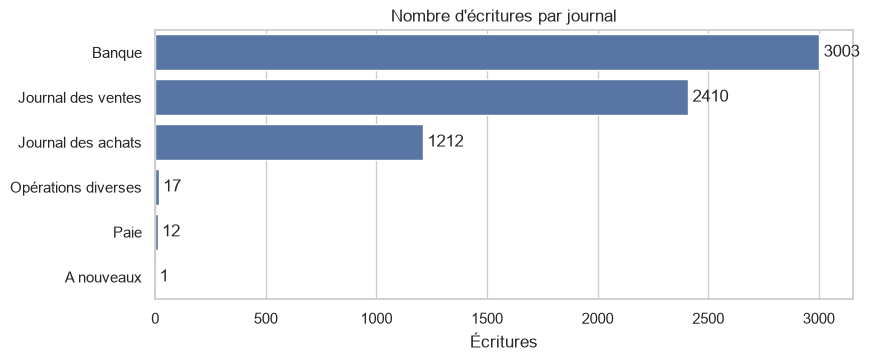

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5))
donnees = par_journal.reset_index()
sns.barplot(data=donnees, y="JournalLib", x="ecritures", color="#4C72B0", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="Nombre d'écritures par journal", xlabel="Écritures", ylabel="")
sauver(fig, "01_ecritures_par_journal")
plt.show()

### 3.2 Saisonnalité du chiffre d'affaires

Le chiffre d'affaires correspond aux comptes **70** (ventes). Ils sont au crédit : on prend donc l'opposé du solde.

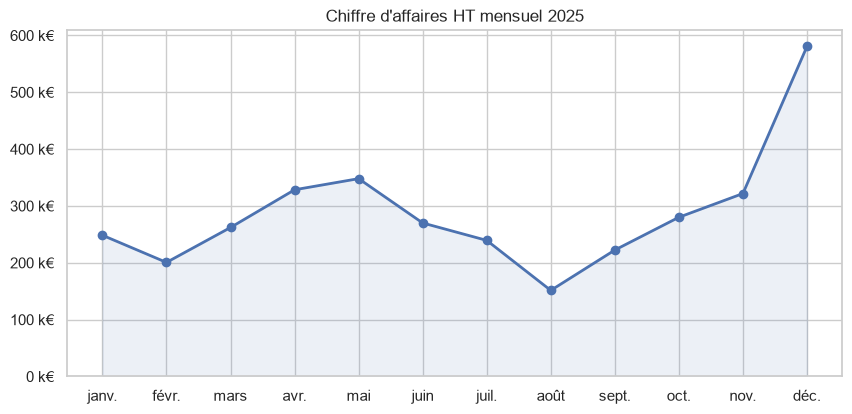

Chiffre d'affaires annuel : 3 453 650 € HT
Part de novembre-décembre : 26%


In [10]:
ventes = fec[fec["CompteNum"].str.startswith("70")]
ca_mensuel = -ventes.groupby(ventes["EcritureDate"].dt.month)["Montant"].sum()

fig, ax = plt.subplots()
ax.plot(MOIS, ca_mensuel.values, marker="o", linewidth=2, color="#4C72B0")
ax.fill_between(MOIS, ca_mensuel.values, alpha=0.1, color="#4C72B0")
ax.yaxis.set_major_formatter(k_euros)
ax.set(title="Chiffre d'affaires HT mensuel 2025", ylabel="")
ax.set_ylim(bottom=0)
sauver(fig, "02_ca_mensuel")
plt.show()

print(f"Chiffre d'affaires annuel : {ca_mensuel.sum():,.0f} € HT".replace(",", " "))
print(f"Part de novembre-décembre : {ca_mensuel.loc[[11, 12]].sum() / ca_mensuel.sum():.0%}")

L'activité est **saisonnière** : un creux en août (vacances) et un pic en fin d'année (fêtes), cohérent pour un distributeur de luminaires.

⚠️ En audit, **un pic de ventes en décembre doit toujours être vérifié** : c'est la période où une entreprise peut être tentée de gonfler son chiffre d'affaires pour embellir ses comptes (*risque de « cut-off »*, c'est-à-dire de séparation des exercices).

### 3.3 Jour de la semaine des écritures

Une entreprise saisit normalement sa comptabilité du lundi au vendredi.

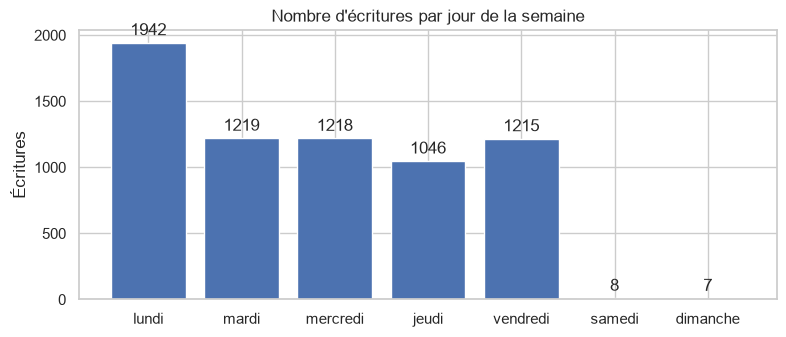

In [11]:
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
ecritures = fec.drop_duplicates("EcritureNum")
par_jour = ecritures["EcritureDate"].dt.day_of_week.value_counts().reindex(range(7), fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.5))
couleurs = ["#4C72B0"] * 5 + ["#C44E52"] * 2
barres = ax.bar(JOURS, par_jour.values, color=couleurs)
ax.bar_label(barres, padding=3)
ax.set(title="Nombre d'écritures par jour de la semaine", ylabel="Écritures")
sauver(fig, "03_ecritures_par_jour")
plt.show()

👉 **Deuxième signal :** quelques écritures sont datées d'un **samedi ou d'un dimanche**. Elles sont peu nombreuses, mais c'est justement ce qui les rend intéressantes : une écriture passée hors des jours ouvrés peut signaler une saisie faite à l'abri des regards. On les isolera à l'étape 3.

Le **lundi** compte plus d'écritures que les autres jours : c'est normal, les règlements bancaires tombant le week-end sont comptabilisés le lundi. Savoir expliquer ce qui est normal évite les fausses alertes.

## 4. Les comptes

### 4.1 Balance générale

La balance donne, pour chaque compte, le total des débits, des crédits et le solde. C'est le point de départ de tout audit des comptes.

In [12]:
balance = (fec.groupby(["CompteNum", "CompteLib"])[["Debit", "Credit"]].sum()
           .assign(Solde=lambda d: d["Debit"] - d["Credit"]))
balance

,,Debit,Credit,Solde
CompteNum,CompteLib,,,
101000,Capital,0.00,50 000.00,-50 000.00
110000,Report à nouveau,0.00,311 000.00,-311 000.00
164000,Emprunts auprès des établissements de crédit,14 400.00,70 000.00,-55 600.00
218300,Matériel de bureau et informatique,60 000.00,0.00,60 000.00
281830,Amortissements du matériel de bureau,0.00,36 000.00,-36 000.00
370000,Stocks de marchandises,45 000.00,0.00,45 000.00
401000,Fournisseurs,2 303 714.62,2 655 530.58,-351 815.96
411000,Clients,4 144 379.65,3 193 328.28,951 051.37
421000,Personnel - rémunérations dues,507 507.00,507 507.00,0.00


### 4.2 Compte de résultat simplifié

In [13]:
def solde(*prefixes):
    return fec.loc[fec["CompteNum"].str.startswith(prefixes), "Montant"].sum()

resultat = pd.Series({
    "Chiffre d'affaires": -solde("70"),
    "Achats de marchandises": -solde("607"),
    "Autres achats et charges externes": -solde("606", "613", "622", "625", "626", "627"),
    "Charges de personnel": -solde("641", "645"),
    "Dotations aux amortissements": -solde("681"),
})
resultat["Résultat avant impôt"] = resultat.sum()

tableau = resultat.to_frame("Montant (€)")
tableau["% du CA"] = (resultat / resultat["Chiffre d'affaires"] * 100).round(1)
tableau

,Montant (€),% du CA
Chiffre d'affaires,3 453 649.65,100.00
Achats de marchandises,-1 984 030.94,-57.40
Autres achats et charges externes,-306 963.02,-8.90
Charges de personnel,-933 842.80,-27.00
Dotations aux amortissements,-12 000.00,-0.30
Résultat avant impôt,216 812.89,6.30


In [14]:
ca = resultat["Chiffre d'affaires"]
marge_brute = ca + resultat["Achats de marchandises"]
print(f"Taux de marge brute : {marge_brute / ca:.1%}")
print(f"Résultat / CA       : {resultat['Résultat avant impôt'] / ca:.1%}")

Taux de marge brute : 42.6%
Résultat / CA       : 6.3%


Ces ratios servent de **référence** : l'auditeur les compare à l'exercice précédent et aux entreprises du secteur. Une marge anormalement élevée ou une évolution brutale oriente les contrôles.

> ℹ️ Ce compte de résultat est simplifié : il n'intègre ni variation de stock, ni impôt sur les sociétés, ni charges financières.

## 5. Montants, clients et délais de paiement

### 5.1 Distribution des montants

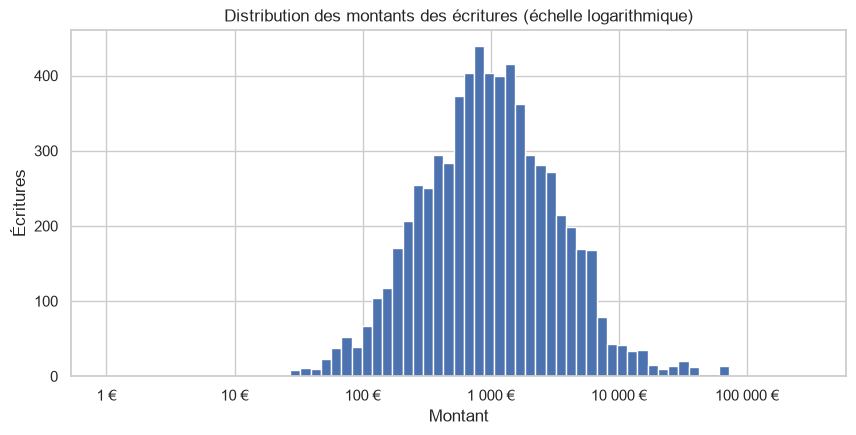

,montant (€)
count,6 655.00
mean,2 289.36
std,7 665.14
min,18.00
25%,430.44
50%,958.37
75%,2 173.06
max,455 000.00


In [15]:
montants = fec.groupby("EcritureNum")["Debit"].sum()
montants = montants[montants > 0]

fig, ax = plt.subplots()
ax.hist(montants, bins=np.logspace(0, 5.5, 70), color="#4C72B0", edgecolor="white")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f} €".replace(",", " ")))
ax.set(title="Distribution des montants des écritures (échelle logarithmique)", xlabel="Montant", ylabel="Écritures")
sauver(fig, "04_distribution_montants")
plt.show()

montants.describe().to_frame("montant (€)")

Les montants s'étalent sur plusieurs ordres de grandeur (de quelques euros à plusieurs dizaines de milliers), avec beaucoup de petits montants et peu de gros. C'est la forme typique des données financières, et la condition pour appliquer la **loi de Benford** (étape 4).

### 5.2 Concentration du chiffre d'affaires par client

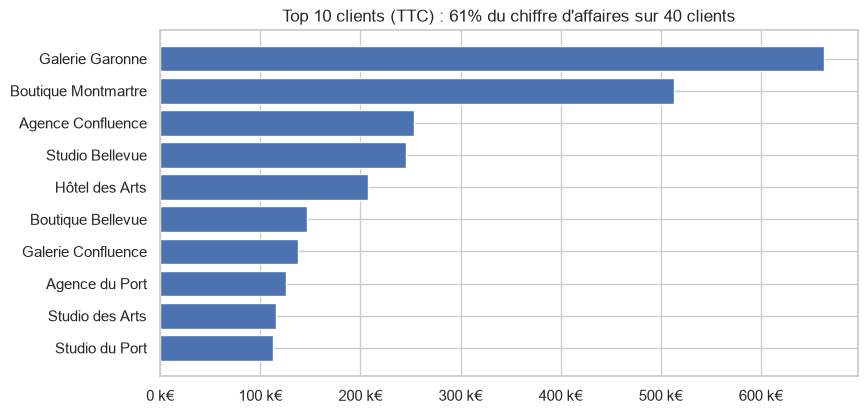

In [16]:
factures_clients = fec[(fec["JournalCode"] == "VE") & (fec["CompteNum"] == "411000")]
ca_client = factures_clients.groupby("CompAuxLib")["Debit"].sum().sort_values(ascending=False)
part_top10 = ca_client.head(10).sum() / ca_client.sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
top = ca_client.head(10).sort_values()
ax.barh(top.index, top.values, color="#4C72B0")
ax.xaxis.set_major_formatter(k_euros)
ax.set(title=f"Top 10 clients (TTC) : {part_top10:.0%} du chiffre d'affaires sur {len(ca_client)} clients")
sauver(fig, "05_top_clients")
plt.show()

### 5.3 Délais d'encaissement clients

Le **lettrage** relie chaque facture à son règlement. L'écart entre la date de facture et la date de lettrage donne le délai d'encaissement réel.

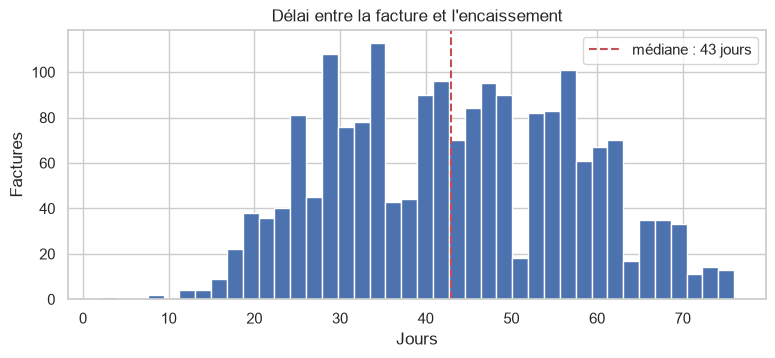

In [17]:
payees = factures_clients[factures_clients["EcritureLet"] != ""]
delais_clients = (payees["DateLet"] - payees["EcritureDate"]).dt.days

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(delais_clients, bins=40, color="#4C72B0", edgecolor="white")
ax.axvline(delais_clients.median(), color="#C44E52", linestyle="--",
           label=f"médiane : {delais_clients.median():.0f} jours")
ax.legend()
ax.set(title="Délai entre la facture et l'encaissement", xlabel="Jours", ylabel="Factures")
sauver(fig, "06_delais_clients")
plt.show()

In [18]:
impayees = factures_clients[factures_clients["EcritureLet"] == ""]
print(f"Factures non encaissées au 31/12 : {len(impayees)} pour "
      f"{impayees['Debit'].sum():,.0f} € TTC".replace(",", " "))
impayees.groupby(impayees["EcritureDate"].dt.month)["Debit"].agg(["count", "sum"]).rename(
    index=dict(enumerate(MOIS, start=1)), columns={"count": "factures", "sum": "montant TTC"})

Factures non encaissées au 31/12 : 501 pour 951 051 € TTC


,factures,montant TTC
EcritureDate,,
janv.,10,12 941.54
févr.,8,8 268.66
mars,6,10 207.85
avr.,10,9 552.13
mai,7,13 487.13
juin,4,2 516.55
juil.,5,9 837.57
août,2,1 078.71
sept.,4,6 995.98


In [19]:
# Les plus grosses factures non encaissées
impayees.nlargest(10, "Debit")[["EcritureNum", "EcritureDate", "PieceRef", "CompAuxLib",
                                "EcritureLib", "Debit", "ValidDate"]]

,EcritureNum,EcritureDate,PieceRef,CompAuxLib,EcritureLib,Debit,ValidDate
7132,VE002376,2025-12-29,FA2025-02376,Hôtel des Arts,Facture FA2025-02376 prestation complémentaire...,29 520.00,2026-01-26
7231,VE002409,2025-12-31,FA2025-02409,Boutique Montmartre,Facture FA2025-02409 prestation complémentaire...,28 920.00,2026-01-15
7228,VE002408,2025-12-31,FA2025-02408,Boutique Montmartre,Facture FA2025-02408 prestation complémentaire...,28 560.00,2026-01-27
7165,VE002387,2025-12-30,FA2025-02387,Boutique Montmartre,Facture FA2025-02387 prestation complémentaire...,26 640.00,2026-01-25
7123,VE002373,2025-12-29,FA2025-02373,Studio du Port,Facture FA2025-02373 prestation complémentaire...,23 760.00,2026-01-17
6517,VE002171,2025-12-09,FA2025-02171,Studio Bellevue,Facture FA2025-02171 Studio Bellevue,22 204.80,2025-12-13
7225,VE002407,2025-12-31,FA2025-02407,Boutique Bellevue,Facture FA2025-02407 prestation complémentaire...,15 000.00,2026-01-13
7234,VE002410,2025-12-31,FA2025-02410,Boutique Montmartre,Facture FA2025-02410 prestation complémentaire...,14 880.00,2026-01-20
5029,VE001675,2025-10-10,FA2025-01676,Galerie Garonne,Facture FA2025-01676 Galerie Garonne,14 630.84,2025-10-13
7126,VE002374,2025-12-29,FA2025-02374,Boutique Bellevue,Facture FA2025-02374 prestation complémentaire...,14 280.00,2026-01-22


👉 **Troisième signal :** il est normal que les factures de novembre-décembre ne soient pas encore payées au 31/12. Mais parmi les plus grosses factures impayées, plusieurs sont datées des **tout derniers jours de l'année**, avec des montants **ronds**, un libellé inhabituel et une **validation tardive** en janvier. C'est exactement le profil d'un risque de *cut-off* à creuser.

### 5.4 Délais de paiement par fournisseur

In [20]:
factures_fournisseurs = fec[(fec["JournalCode"] == "AC") & (fec["CompteNum"] == "401000")
                            & (fec["Credit"] > 0)]
payees_f = factures_fournisseurs[factures_fournisseurs["EcritureLet"] != ""]

profil_fournisseurs = (payees_f.assign(delai=(payees_f["DateLet"] - payees_f["EcritureDate"]).dt.days)
                       .groupby(["CompAuxNum", "CompAuxLib"])
                       .agg(factures=("delai", "size"),
                            delai_median_jours=("delai", "median"),
                            montant_moyen_TTC=("Credit", "mean"),
                            premiere_facture=("EcritureDate", "min"))
                       .sort_values("delai_median_jours"))
profil_fournisseurs.head(8)

,,factures,delai_median_jours,montant_moyen_TTC,premiere_facture
CompAuxNum,CompAuxLib,,,,
F0099,Conseil Stratégie Plus,14,6.00,5 834.89,2025-06-13
F0022,SCI Les Tilleuls,12,6.50,4 200.00,2025-01-02
F0023,Cabinet Expertise Comptable Martin,3,15.00,2 880.00,2025-03-31
F0005,Manufacture Atlas,43,40.00,2 410.40,2025-01-13
F0018,Comptoir Éclat,37,42.00,2 845.29,2025-01-02
F0002,Import Éclat,41,42.00,2 557.30,2025-01-07
F0003,Comptoir Atlas,37,42.00,3 467.38,2025-01-07
F0001,Fabrique Atlas,51,43.00,2 929.20,2025-01-03


👉 **Quatrième signal :** la plupart des fournisseurs sont payés à 30-60 jours. Un fournisseur sort clairement du lot : **payé en quelques jours**, apparu **en cours d'année**, avec des factures d'un montant moyen **proche du seuil de 5 000 € HT** (environ 6 000 € TTC). Un fournisseur récent, payé très vite, dont les factures sont toutes juste sous le seuil d'approbation, est un schéma classique de **fournisseur fictif**.

Le bailleur (SCI Les Tilleuls) est lui aussi payé vite, mais c'est explicable : un loyer fixe, mensuel, connu depuis le début de l'année. L'auditeur ne s'arrête pas à un indicateur, il **croise plusieurs signaux**.

## 6. Bilan de l'exploration

| Constat | Risque d'audit | Test prévu à l'étape 3 |
|---|---|---|
| Écart débit ≠ crédit sur quelques écritures | Erreur de saisie, contrôle logiciel défaillant | Contrôle d'équilibre des écritures |
| Écritures datées le week-end | Saisie hors contrôle | Test des jours non ouvrés |
| Grosses ventes impayées des derniers jours, validées en janvier | Chiffre d'affaires fictif (cut-off) | Écritures de fin d'exercice + validation tardive |
| Fournisseur récent payé en quelques jours, factures proches de 5 000 € HT | Fournisseur fictif, contournement du seuil d'approbation | Montants juste sous le seuil, nouveaux fournisseurs |
| Montants très dispersés | Base adaptée à la loi de Benford | Test de Benford (étape 4) |

**Ce qu'on a appris sans aucun modèle :** une simple exploration bien menée met déjà en évidence plusieurs zones de risque. L'étape 3 va transformer ces intuitions en **tests systématiques**, appliqués à 100 % des écritures, puis mesurer combien d'anomalies cachées ils retrouvent.